# Paket E — D8 Difüzyon süresi
Maskeden önce doğrusal difüzyon: 0, 10, 40 adım, adım büyüklüğü 0,20, her renk kanalı ayrı.
t = adım × 0,20; sürekli çözüm σ = √(2t) olan Gauss'tur → 40 adım (t = 8) ≈ Gauss σ = 4.
Yalnız difüzyon adım sayısı değişir; B'nin filtresi dahil diğer ayarlar aynıdır.

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [5]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


,govde_maske_orani,canny_orani
islem,,
Gauss σ=4,0.176,0.007
difüzyon 0 adım,0.174,0.115
difüzyon 10 adım,0.181,0.039
difüzyon 40 adım,0.175,0.007


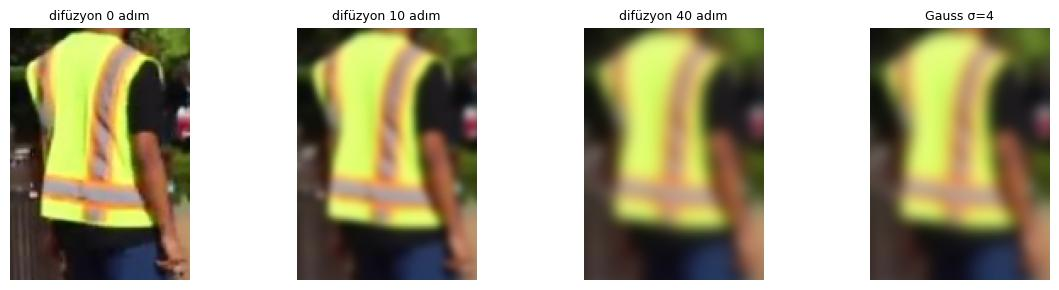

In [6]:
import experiments
d8 = experiments.d8(CTRL_IDS, gt, P, kisi='E', show_id='K-1')
d8.groupby('islem')[['govde_maske_orani', 'canny_orani']].mean().round(3)

In [7]:
d8.pivot_table(index='id', columns='islem', values=['govde_maske_orani', 'canny_orani']).round(3)

canny_orani                                                    \
islem   Gauss σ=4 difüzyon 0 adım difüzyon 10 adım difüzyon 40 adım   
id                                                                    
K-1         0.020           0.115            0.051            0.022   
K-10        0.012           0.107            0.035            0.011   
K-11        0.005           0.145            0.045            0.006   
K-12        0.011           0.020            0.016            0.010   
K-2         0.005           0.042            0.020            0.004   
K-3         0.010           0.038            0.018            0.009   
K-4         0.006           0.295            0.136            0.007   
K-5         0.008           0.146            0.034            0.008   
K-6         0.001           0.108            0.041            0.001   
K-7         0.002           0.034            0.013            0.001   
K-8         0.000           0.136            0.034            0.000   
K-9         0.009           0.195            0.032            0.009   

      govde_maske_orani                                                    
islem         Gauss σ=4 difüzyon 0 adım difüzyon 10 adım difüzyon 40 adım  
id                                                                         
K-1               0.405           0.367            0.384            0.406  
K-10              0.129           0.125            0.127            0.129  
K-11              0.040           0.045            0.042            0.040  
K-12              0.000           0.000            0.000            0.000  
K-2               0.525           0.509            0.516            0.526  
K-3               0.058           0.068            0.065            0.058  
K-4               0.407           0.356            0.438            0.405  
K-5               0.065           0.086            0.079            0.065  
K-6               0.149           0.196            0.181            0.149  
K-7               0.292           0.297            0.294            0.291  
K-8               0.015           0.017            0.017            0.015  
K-9               0.023           0.025            0.024            0.023

In [8]:
# 40 adım ile Gauss σ=4 arasındaki ortalama mutlak piksel farkı (0–255 ölçeğinde)
d8[d8.islem.str.startswith('Gauss')][['id', 'fark_difuzyon40_mae']]

,id,fark_difuzyon40_mae
3,K-1,0.067814
7,K-2,0.031660
11,K-3,0.063579
15,K-4,0.082030
19,K-5,0.135279
23,K-6,0.099775
27,K-7,0.027001
31,K-8,0.198731
35,K-9,0.088081
39,K-10,0.078856


**Neden kenarlar yayılıyor?** Isı denklemi u_t = Δu her pikseli komşularının ortalamasına çeker; t arttıkça
etkin Gauss genişliği σ = √(2t) büyür ve basamak biçimli şerit kenarı σ genişliğinde bir rampaya dönüşür. Gradyan
tepesi düşer, Canny'nin yüksek eşiğini geçemez ya da kenar kayar. Doğrusal difüzyon yön gözetmez (izotropik);
kenarı koruyan bilateral/medyan filtreden bu yüzden ayrılır (S6).